<a href="https://colab.research.google.com/github/manukondanagendra/eda/blob/main/internal_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("/content/employee_attrition_classification.csv")
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   department              241 non-null    object 
 1   work_accident           241 non-null    object 
 2   emp_id                  241 non-null    object 
 3   left_company            241 non-null    float64
 4   salary_k                241 non-null    float64
 5   education_level         241 non-null    object 
 6   promotion_last_5years   241 non-null    object 
 7   years_at_company        241 non-null    float64
 8   salary_k_dup            241 non-null    float64
 9   last_performance_score  241 non-null    float64
dtypes: float64(5), object(5)
memory usage: 19.0+ KB


describes

In [147]:
df.describe()

,left_company,salary_k,years_at_company,salary_k_dup,last_performance_score
count,241.000000,241.000000,241.000000,241.000000,241.000000
mean,0.195021,107.757220,15.294606,107.757220,3.037344
std,0.397041,51.557736,7.825195,51.557736,1.370316
min,0.000000,20.590000,0.000000,20.590000,1.000000
25%,0.000000,64.540000,9.000000,64.540000,2.000000
50%,0.000000,100.185000,15.000000,100.185000,3.000000
75%,0.000000,157.490000,22.000000,157.490000,4.000000
max,1.000000,199.530000,29.000000,199.530000,5.000000


first 5 rowa


In [148]:
df.head()

,department,work_accident,emp_id,left_company,salary_k,education_level,promotion_last_5years,years_at_company,salary_k_dup,last_performance_score
0,Finance,No,E60000,0.0,53.06,Bachelors,No,14.0,53.06,1.0
1,Support,No,E60001,1.0,82.23,PhD,No,16.0,82.23,3.0
2,Finance,No,E60002,0.0,165.15,Masters,No,14.0,165.15,4.0
3,Sales,No,E60004,1.0,39.74,Bachelors,No,27.0,39.74,4.0
4,HR,No,E60007,0.0,36.24,Masters,Yes,16.0,36.24,4.0


last five rows

In [149]:
df.tail()

,department,work_accident,emp_id,left_company,salary_k,education_level,promotion_last_5years,years_at_company,salary_k_dup,last_performance_score
236,HR,Yes,E60086,0.0,64.77,PhD,No,9.0,64.77,5.0
237,HR,No,E60139,0.0,189.30,PhD,No,11.0,189.30,3.0
238,Finance,No,E60126,0.0,98.89,PhD,No,7.0,98.89,2.0
239,Sales,Yes,E60076,1.0,168.88,High School,No,27.0,168.88,2.0
240,Finance,No,E60098,0.0,55.46,PhD,No,15.0,55.46,2.0


finding the missing value in each row

In [150]:
df.isnull().sum()

,0
department,0
work_accident,0
emp_id,0
left_company,0
salary_k,0
education_level,0
promotion_last_5years,0
years_at_company,0
salary_k_dup,0
last_performance_score,0


converting to unique attributes

In [151]:
df['department'].unique()

array(['Finance', 'Support', 'Sales', 'HR', 'Engineering'], dtype=object)

In [152]:
df['department'].replace({
    'FINANCE': 'Finance', 'Finace': 'Finance', 'Financ': 'Finance', 'inance': 'Finance',
    'SUPPORT': 'Support', 'Suppot': 'Support', 'Suport': 'Support', 'Sals': 'Support', 'upport': 'Support', 'Spport': 'Support', 'Suppor': 'Support',
    'SALES': 'Sales', 'Saes': 'Sales', 'ales': 'Sales',
    'ENGINEERING': 'Engineering', 'Engineerig': 'Engineering', 'Engneering': 'Engineering',
    'Hr': 'HR', 'H': 'HR', 'R': 'HR'
}, inplace=True)

print(df['department'].unique())

['Finance' 'Support' 'Sales' 'HR' 'Engineering']


/tmp/ipykernel_4537/917750281.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['department'].replace({


In [153]:
df['work_accident'].unique()

array(['No', 'Yes'], dtype=object)

In [154]:
df['work_accident'].replace({'N':'No','NO':'No','o':'No'},inplace=True)

/tmp/ipykernel_4537/2468536348.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['work_accident'].replace({'N':'No','NO':'No','o':'No'},inplace=True)


In [155]:
df['education_level'].unique()

array(['Bachelors', 'PhD', 'Masters', 'High School'], dtype=object)

In [156]:
df['education_level'] = df['education_level'].replace({'BACHELORS': 'Bachelors','Bacelors': 'Bachelors','Bachlors': 'Bachelors','Bachelos': 'Bachelors','Bahelors': 'Bachelors',
    'Bacheors': 'Bachelors','achelors': 'Bachelors','MASTERS': 'Masters','Msters': 'Masters','Maters': 'Masters','Masers': 'Masters','PHD': 'PhD','Phd': 'PhD','Ph': 'PhD',
    'hD': 'PhD','PD': 'PhD','HIGH SCHOOL': 'High School','High school': 'High School','HighSchool': 'High School','High chool': 'High School','High Scool': 'High School',
    'igh School': 'High School','High Schol': 'High School','Hig School': 'High School'
})

In [157]:
df['promotion_last_5years'].unique()

array(['No', 'Yes'], dtype=object)

In [158]:
df['promotion_last_5years'].replace({'NO':'No','o':'No','N':'No','es':'Yes','Ye':'Yes','YES':'Yes'},inplace=True)

/tmp/ipykernel_4537/463179554.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['promotion_last_5years'].replace({'NO':'No','o':'No','N':'No','es':'Yes','Ye':'Yes','YES':'Yes'},inplace=True)


replacing with null value by using mean,median,mode

In [159]:
cat_cols = [
    'department',
    'work_accident',
    'left_company',
    'education_level',
    'promotion_last_5years'
]

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [160]:
num_cols = [
    'salary_k',
    'years_at_company',
    'salary_k_dup',
    'last_performance_score'
]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
df

,department,work_accident,emp_id,left_company,salary_k,education_level,promotion_last_5years,years_at_company,salary_k_dup,last_performance_score
0,Finance,No,E60000,0.0,53.06,Bachelors,No,14.0,53.06,1.0
1,Support,No,E60001,1.0,82.23,PhD,No,16.0,82.23,3.0
2,Finance,No,E60002,0.0,165.15,Masters,No,14.0,165.15,4.0
3,Sales,No,E60004,1.0,39.74,Bachelors,No,27.0,39.74,4.0
4,HR,No,E60007,0.0,36.24,Masters,Yes,16.0,36.24,4.0
...,...,...,...,...,...,...,...,...,...,...
236,HR,Yes,E60086,0.0,64.77,PhD,No,9.0,64.77,5.0
237,HR,No,E60139,0.0,189.30,PhD,No,11.0,189.30,3.0
238,Finance,No,E60126,0.0,98.89,PhD,No,7.0,98.89,2.0
239,Sales,Yes,E60076,1.0,168.88,High School,No,27.0,168.88,2.0


emp_id is combine with numberical and categorical so we can droped

In [161]:
df = df.dropna(subset=['emp_id'])

In [162]:
df.isnull().sum()

,0
department,0
work_accident,0
emp_id,0
left_company,0
salary_k,0
education_level,0
promotion_last_5years,0
years_at_company,0
salary_k_dup,0
last_performance_score,0


duplicate values

In [163]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
236,True
237,True
238,True
239,True


remove duplicate values

In [164]:
df.drop_duplicates()

,department,work_accident,emp_id,left_company,salary_k,education_level,promotion_last_5years,years_at_company,salary_k_dup,last_performance_score
0,Finance,No,E60000,0.0,53.06,Bachelors,No,14.0,53.06,1.0
1,Support,No,E60001,1.0,82.23,PhD,No,16.0,82.23,3.0
2,Finance,No,E60002,0.0,165.15,Masters,No,14.0,165.15,4.0
3,Sales,No,E60004,1.0,39.74,Bachelors,No,27.0,39.74,4.0
4,HR,No,E60007,0.0,36.24,Masters,Yes,16.0,36.24,4.0
...,...,...,...,...,...,...,...,...,...,...
225,HR,No,E60244,0.0,36.83,Bachelors,No,14.0,36.83,3.0
226,Engineering,No,E60245,1.0,116.19,Masters,No,21.0,116.19,1.0
227,Finance,No,E60246,0.0,109.68,PhD,No,29.0,109.68,2.0
228,Sales,No,E60247,0.0,82.49,Bachelors,No,4.0,82.49,1.0


In [165]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers))

left_company : 47
salary_k : 0
years_at_company : 0
salary_k_dup : 0
last_performance_score : 0


In [166]:
df

,department,work_accident,emp_id,left_company,salary_k,education_level,promotion_last_5years,years_at_company,salary_k_dup,last_performance_score
0,Finance,No,E60000,0.0,53.06,Bachelors,No,14.0,53.06,1.0
1,Support,No,E60001,1.0,82.23,PhD,No,16.0,82.23,3.0
2,Finance,No,E60002,0.0,165.15,Masters,No,14.0,165.15,4.0
3,Sales,No,E60004,1.0,39.74,Bachelors,No,27.0,39.74,4.0
4,HR,No,E60007,0.0,36.24,Masters,Yes,16.0,36.24,4.0
...,...,...,...,...,...,...,...,...,...,...
236,HR,Yes,E60086,0.0,64.77,PhD,No,9.0,64.77,5.0
237,HR,No,E60139,0.0,189.30,PhD,No,11.0,189.30,3.0
238,Finance,No,E60126,0.0,98.89,PhD,No,7.0,98.89,2.0
239,Sales,Yes,E60076,1.0,168.88,High School,No,27.0,168.88,2.0


In [167]:
df.to_csv("employee_attrition_classification.csv", index=False)

print("Preprocessed dataset saved successfully")

Preprocessed dataset saved successfully


In [168]:
from google.colab import files

df.to_csv('preprocessed_dataset.csv', index=False)
files.download('preprocessed_dataset.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [169]:
pd.read_csv("/content/preprocessed_dataset.csv")

,department,work_accident,emp_id,left_company,salary_k,education_level,promotion_last_5years,years_at_company,salary_k_dup,last_performance_score
0,Finance,No,E60000,0.0,53.06,Bachelors,No,14.0,53.06,1.0
1,Support,No,E60001,1.0,82.23,PhD,No,16.0,82.23,3.0
2,Finance,No,E60002,0.0,165.15,Masters,No,14.0,165.15,4.0
3,Sales,No,E60004,1.0,39.74,Bachelors,No,27.0,39.74,4.0
4,HR,No,E60007,0.0,36.24,Masters,Yes,16.0,36.24,4.0
...,...,...,...,...,...,...,...,...,...,...
236,HR,Yes,E60086,0.0,64.77,PhD,No,9.0,64.77,5.0
237,HR,No,E60139,0.0,189.30,PhD,No,11.0,189.30,3.0
238,Finance,No,E60126,0.0,98.89,PhD,No,7.0,98.89,2.0
239,Sales,Yes,E60076,1.0,168.88,High School,No,27.0,168.88,2.0


histogram

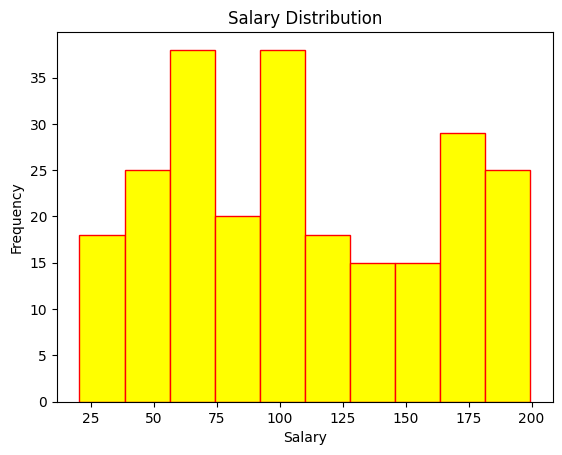

In [170]:
plt.hist(df['salary_k'], bins=10,edgecolor="red",color="yellow")
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.show()

boxplot

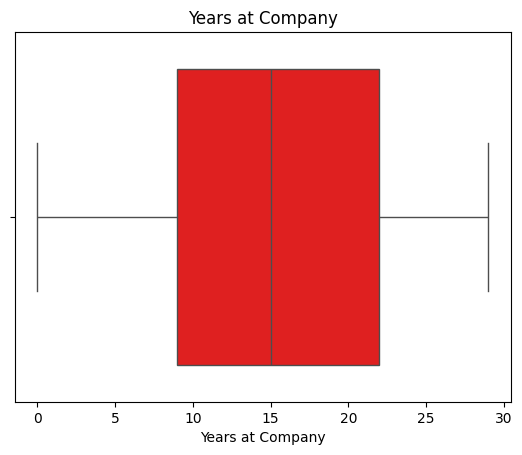

In [171]:
sns.boxplot(x=df['years_at_company'],color="red")
plt.xlabel("Years at Company")
plt.title("Years at Company")
plt.show()

countplot

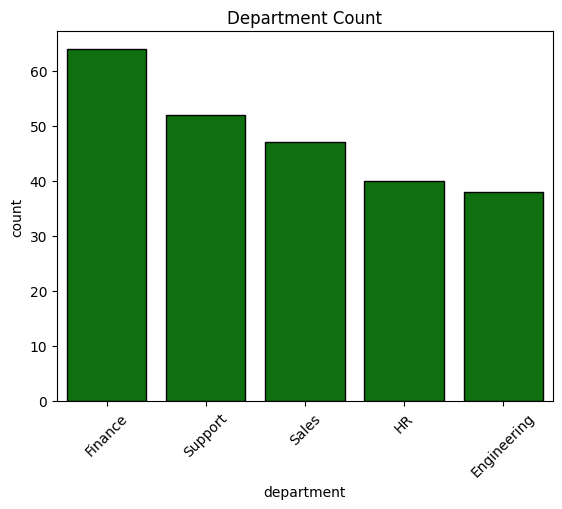

In [172]:
sns.countplot(data=df, x='department',edgecolor="black",color="green")
plt.title("Department Count")
plt.xticks(rotation=45)
plt.show()

scatterplot

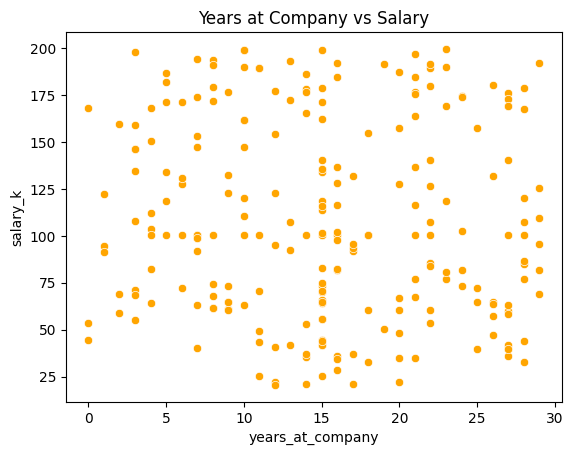

In [173]:
sns.scatterplot(data=df, x='years_at_company',
                y='salary_k',color="orange")

plt.title("Years at Company vs Salary")
plt.show()

barchart

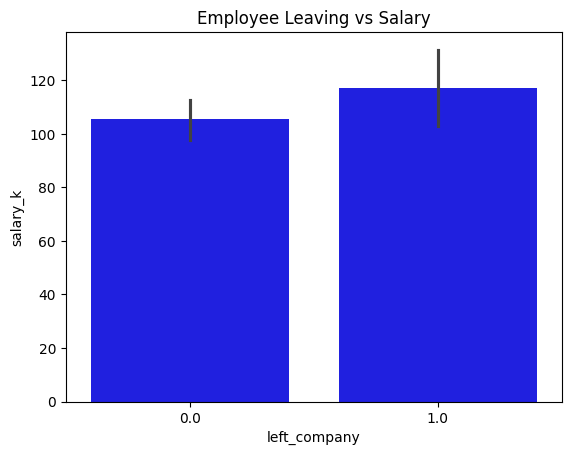

In [174]:
sns.barplot(data=df, x='left_company',
            y='salary_k',color="blue")

plt.title("Employee Leaving vs Salary")
plt.show()

box plot

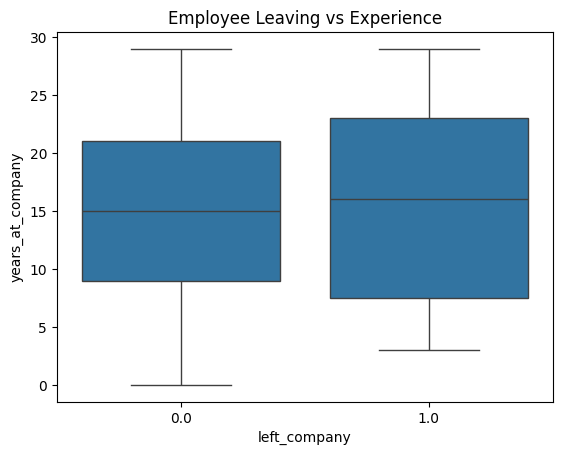

In [175]:
sns.boxplot(data=df, x='left_company',
            y='years_at_company')

plt.title("Employee Leaving vs Experience")
plt.show()

correlation

heatmap

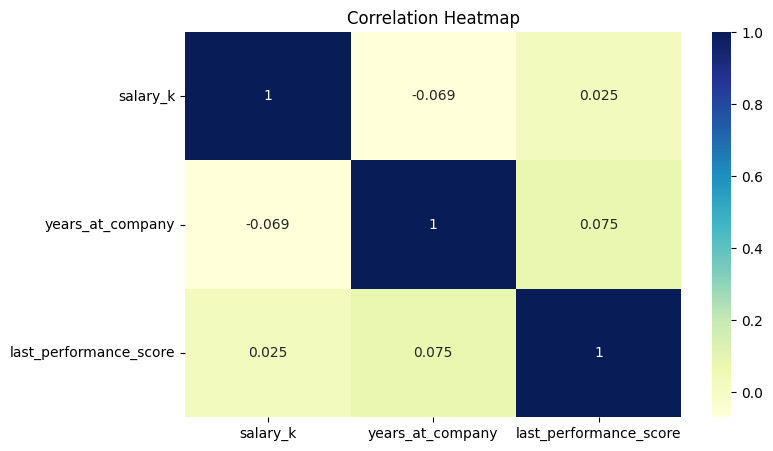

In [176]:
corr = df[['salary_k',
           'years_at_company',
           'last_performance_score']].corr()

plt.figure(figsize=(8,5))
sns.heatmap(corr, annot=True, cmap='YlGnBu')

plt.title("Correlation Heatmap")
plt.show()

pairplot

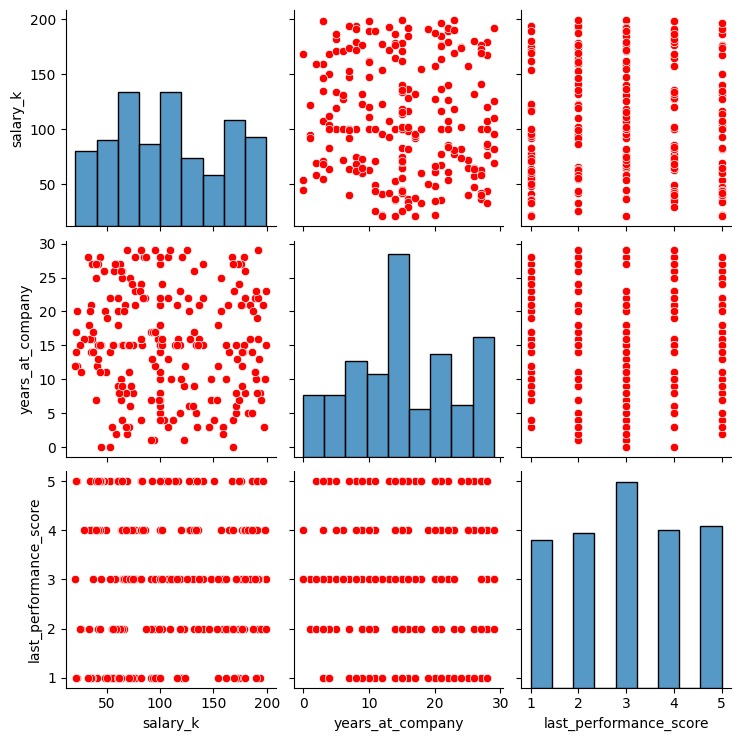

In [177]:
sns.pairplot(df[['salary_k',
                 'years_at_company',
                 'last_performance_score']], plot_kws={'color':'red'})

plt.show()

3d scatterplot

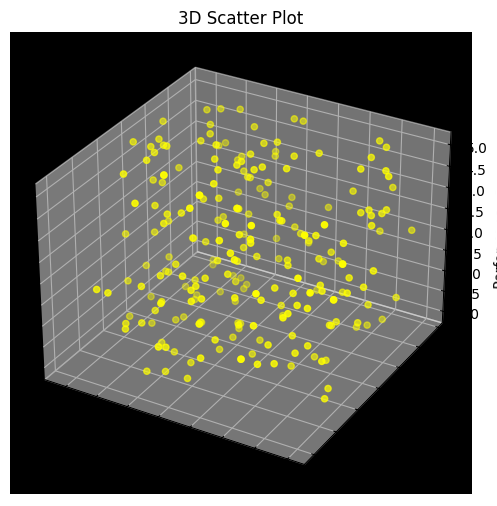

In [178]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d', facecolor='black')
ax.scatter(df['salary_k'],
           df['years_at_company'],
           df['last_performance_score'],
           color='yellow')

ax.set_xlabel('Salary')
ax.set_ylabel('Years at Company')
ax.set_zlabel('Performance Score')

plt.title("3D Scatter Plot")
plt.show()

Final Report

We explored the employee dataset using Python tools like Pandas, NumPy, Matplotlib, and Seaborn. By combining statistical analysis with clear visualizations, we were able to get a deeper understanding of the workforce.

The study revealed how employees are distributed across departments, highlighted salary trends, and showed how work experience relates to pay and attrition. The charts and graphs made these patterns easy to spot, helping us see connections between different factors—like how experience influences retention or how salaries vary across roles.

Conclusion:

The project successfully completed the preprocessing, statistical analysis, and visualization of the employee dataset. Missing values, duplicate entries, and outliers were identified and treated using appropriate methods. Various charts and graphs were created to understand data patterns, trends, and relationships. Overall, the project helped improve data quality and provided meaningful insights into employee information through effective data analysis.